C:\Users\toni2\AppData\Local\Temp\ipykernel_10812\732002036.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_gwh, x='Uni', y='Total_GWh', ax=ax4, palette='Pastel1', boxprops=dict(alpha=0.8))


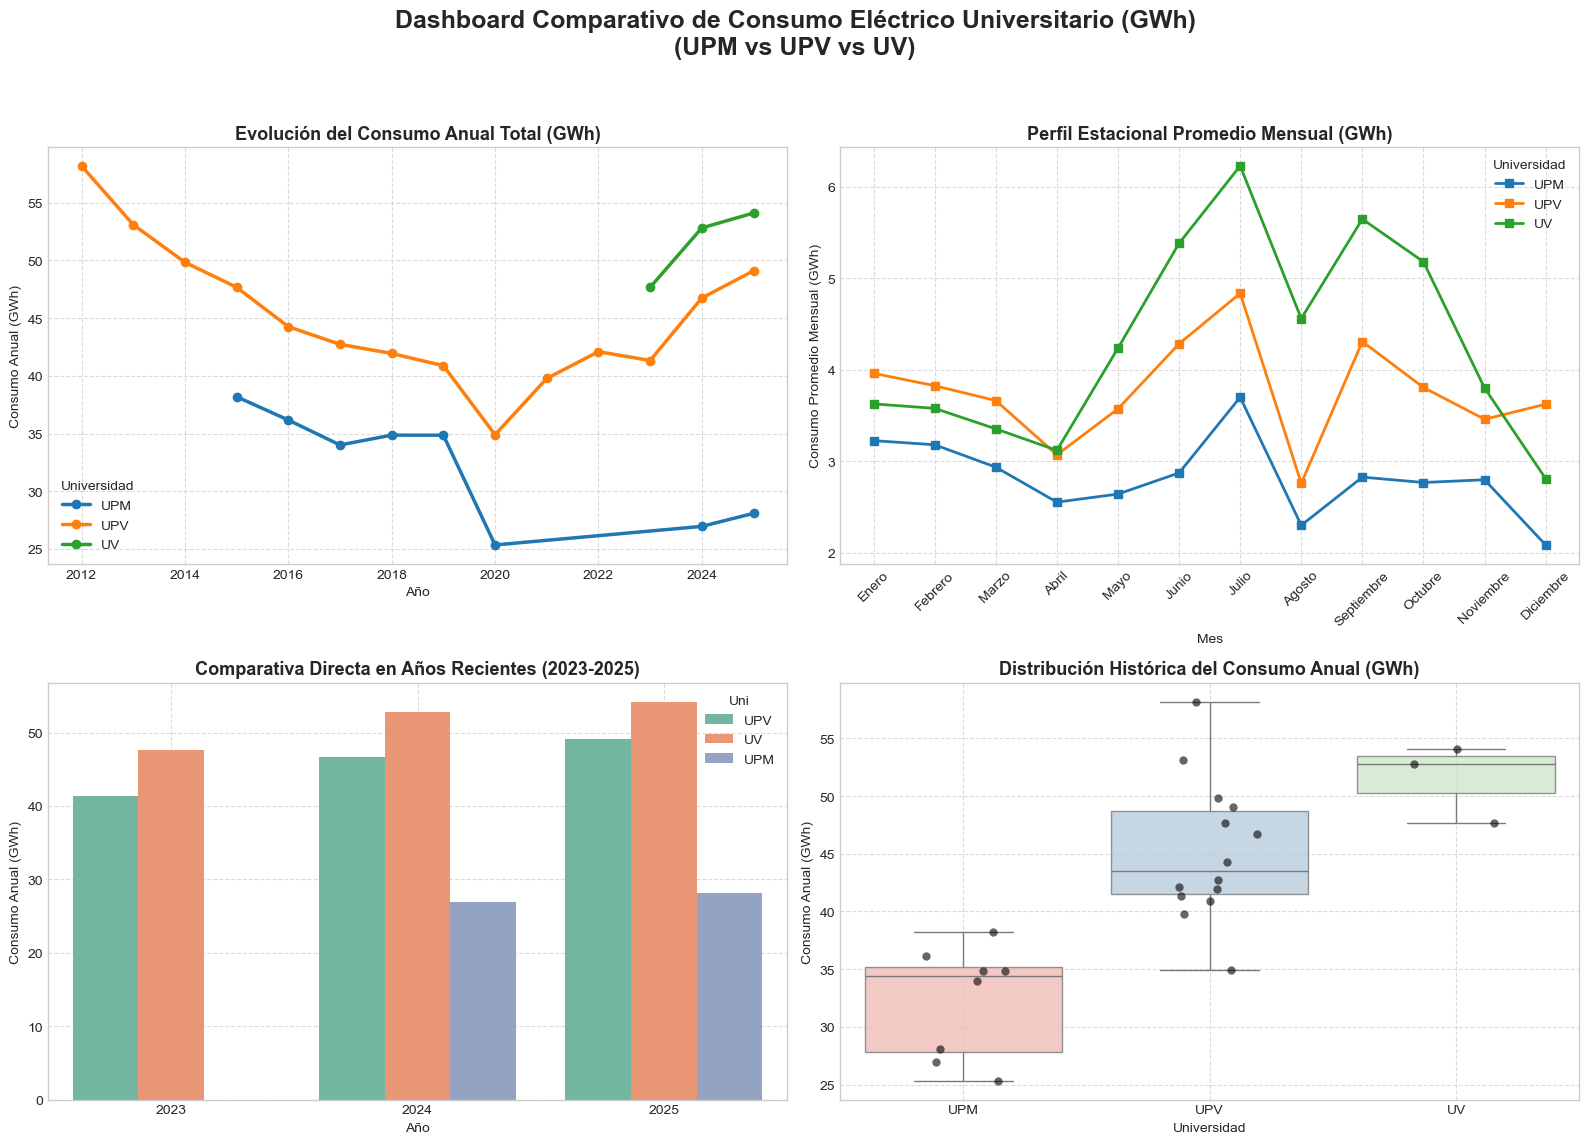

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar datos
excel_path = 'datos_energia_combinado.xlsx'
df = pd.read_excel(excel_path)

# Limpiar nombres de columnas (eliminar espacios en blanco adicionales)
df.columns = df.columns.str.strip()

# Meses del año
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 
         'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

# Convertir de kWh a GWh para mejorar la legibilidad gráfica
df_gwh = df.copy()
df_gwh['Total_GWh'] = df_gwh['Total'] / 1e6
for m in meses:
    df_gwh[m] = df_gwh[m] / 1e6

# 2. Configurar la figura del Dashboard
plt.style.use('seaborn-v0_8-whitegrid')
fig = plt.figure(figsize=(16, 12))
fig.suptitle('Dashboard Comparativo de Consumo Eléctrico Universitario (GWh)\n(UPM vs UPV vs UV)', 
             fontsize=18, fontweight='bold', y=0.98)

# Subplot 1: Evolución Temporal del Consumo Anual Total
ax1 = plt.subplot(2, 2, 1)
for uni in df_gwh['Uni'].unique():
    sub = df_gwh[df_gwh['Uni'] == uni].sort_values('Año')
    ax1.plot(sub['Año'], sub['Total_GWh'], marker='o', linewidth=2.5, label=uni)
ax1.set_title('Evolución del Consumo Anual Total (GWh)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Año')
ax1.set_ylabel('Consumo Anual (GWh)')
ax1.legend(title='Universidad')
ax1.grid(True, linestyle='--', alpha=0.7)

# Subplot 2: Perfil Estacional Promedio Mensual
ax2 = plt.subplot(2, 2, 2)
monthly_avg = df_gwh.groupby('Uni')[meses].mean()
for uni in monthly_avg.index:
    ax2.plot(meses, monthly_avg.loc[uni], marker='s', linewidth=2, label=uni)
ax2.set_title('Perfil Estacional Promedio Mensual (GWh)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Mes')
ax2.set_ylabel('Consumo Promedio Mensual (GWh)')
ax2.set_xticks(range(len(meses)))
ax2.set_xticklabels(meses, rotation=45)
ax2.legend(title='Universidad')
ax2.grid(True, linestyle='--', alpha=0.7)

# Subplot 3: Comparativa Directa en Años Recientes (2023-2025)
ax3 = plt.subplot(2, 2, 3)
recent_df = df_gwh[df_gwh['Año'].isin([2023, 2024, 2025])]
sns.barplot(data=recent_df, x='Año', y='Total_GWh', hue='Uni', ax=ax3, palette='Set2')
ax3.set_title('Comparativa Directa en Años Recientes (2023-2025)', fontsize=13, fontweight='bold')
ax3.set_xlabel('Año')
ax3.set_ylabel('Consumo Anual (GWh)')
ax3.grid(True, linestyle='--', alpha=0.7)

# Subplot 4: Distribución Histórica del Consumo Anual (Boxplot)
ax4 = plt.subplot(2, 2, 4)
sns.boxplot(data=df_gwh, x='Uni', y='Total_GWh', ax=ax4, palette='Pastel1', boxprops=dict(alpha=0.8))
sns.stripplot(data=df_gwh, x='Uni', y='Total_GWh', ax=ax4, color='black', alpha=0.6, jitter=0.2, size=6)
ax4.set_title('Distribución Histórica del Consumo Anual (GWh)', fontsize=13, fontweight='bold')
ax4.set_xlabel('Universidad')
ax4.set_ylabel('Consumo Anual (GWh)')
ax4.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [2]:
pip install dash plotly pandas openpyxl

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 6.4 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.3 MB 11.0 MB/s eta 0:00:01
   ----------------------------- ---------- 6.8/9.3 MB 12.6 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 12.8 MB/s  0:00:00

   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   ------------------

In [9]:
import dash
from dash import dcc, html, dash_table
from dash.dependencies import Input, Output
import plotly.express as px
import pandas as pd
import os

# 1. Cargar datos desde el archivo Excel
excel_path = 'datos_energia_combinado.xlsx'

if not os.path.exists(excel_path):
    print(f"ERROR: No se encuentra el archivo '{excel_path}' en el directorio actual.")
    print("Asegúrate de colocar este script en la misma carpeta que el archivo Excel.")
else:
    df = pd.read_excel(excel_path)
    df.columns = df.columns.str.strip()

meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 
         'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

# 2. Inicializar la app Dash
app = dash.Dash(__name__, title="Dashboard Energético Universitario")

# Estilos visuales inline (Sidebar + Área de Contenido)
SIDEBAR_STYLE = {
    "position": "fixed",
    "top": 0, "left": 0, "bottom": 0,
    "width": "20rem", "padding": "2rem 1.5rem",
    "background-color": "#1e293b", "color": "#f8fafc",
    "boxShadow": "4px 0 10px rgba(0,0,0,0.1)",
    "overflowY": "auto"
}

CONTENT_STYLE = {
    "margin-left": "21rem", "margin-right": "2rem",
    "padding": "2rem 1rem", "background-color": "#f8fafc",
    "minHeight": "100vh"
}

# 3. Estructura visual de la app
app.layout = html.Div([
    # Panel Lateral (Filtros)
    html.Div([
        html.H2("EnergyDash", style={"color": "#38bdf8", "fontWeight": "bold"}),
        html.P("Panel de Control Energético", style={"color": "#94a3b8", "fontSize": "0.9rem"}),
        html.Hr(style={"borderColor": "#334155"}),
        
        html.Label("Universidades:", style={"fontWeight": "bold", "color": "#e2e8f0"}),
        dcc.Dropdown(
            id='dropdown-unis',
            options=[{'label': u, 'value': u} for u in df['Uni'].unique()],
            value=list(df['Uni'].unique()),
            multi=True,
            style={"color": "#0f172a", "marginBottom": "1.5rem"}
        ),
        
        html.Label("Rango de Años:", style={"fontWeight": "bold", "color": "#e2e8f0"}),
        dcc.RangeSlider(
            id='slider-anios',
            min=int(df['Año'].min()),
            max=int(df['Año'].max()),
            step=1,
            value=[int(df['Año'].min()), int(df['Año'].max())],
            marks={int(a): str(a) for a in sorted(df['Año'].unique()) if a % 2 == 0 or a == df['Año'].max()}
        ),
        html.Div(style={"marginBottom": "2rem"}),
        
        html.Label("Unidad de Medida:", style={"fontWeight": "bold", "color": "#e2e8f0"}),
        dcc.RadioItems(
            id='radio-unidad',
            options=[
                {'label': ' Gigavatios-hora (GWh)', 'value': 'GWh'},
                {'label': ' Kilovatios-hora (kWh)', 'value': 'kWh'}
            ],
            value='GWh',
            labelStyle={'display': 'block', 'margin-top': '8px', 'color': '#cbd5e1'}
        ),
    ], style=SIDEBAR_STYLE),

    # Área de Contenido Principal
    html.Div([
        html.Div([
            html.H1("Comparativa de Consumo Eléctrico Universitario", style={"color": "#0f172a", "fontWeight": "bold"}),
            html.P("Análisis multianual de consumo energético en UPM, UPV y UV", style={"color": "#64748b"})
        ], style={"marginBottom": "2rem"}),

        # Tarjetas KPI
        html.Div(id='kpi-cards', style={
            "display": "grid", "gridTemplateColumns": "repeat(auto-fit, minmax(220px, 1fr))", 
            "gap": "1.5rem", "marginBottom": "2rem"
        }),

        # Pestañas con Gráficos Interactivos
        dcc.Tabs([
            dcc.Tab(label='Evolución Anual', children=[
                dcc.Graph(id='graph-evolucion', style={"marginTop": "1.5rem"})
            ]),
            dcc.Tab(label='Perfil Estacional Mensual', children=[
                dcc.Graph(id='graph-estacional', style={"marginTop": "1.5rem"})
            ]),
            dcc.Tab(label='Comparativa Directa', children=[
                dcc.Graph(id='graph-comparativa', style={"marginTop": "1.5rem"})
            ]),
            dcc.Tab(label='Tabla de Datos', children=[
                html.Div(id='tabla-container', style={"marginTop": "1.5rem"})
            ]),
        ])
    ], style=CONTENT_STYLE)
])

# 4. Interactividad (Callbacks)
@app.callback(
    [Output('kpi-cards', 'children'),
     Output('graph-evolucion', 'figure'),
     Output('graph-estacional', 'figure'),
     Output('graph-comparativa', 'figure'),
     Output('tabla-container', 'children')],
    [Input('dropdown-unis', 'value'),
     Input('slider-anios', 'value'),
     Input('radio-unidad', 'value')]
)
def update_dashboard(selected_unis, year_range, unit):
    if not selected_unis:
        selected_unis = list(df['Uni'].unique())
        
    dff = df[(df['Uni'].isin(selected_unis)) & 
             (df['Año'] >= year_range[0]) & 
             (df['Año'] <= year_range[1])].copy()

    factor = 1e6 if unit == 'GWh' else 1
    dff_unit = dff.copy()
    dff_unit['Total_Val'] = dff_unit['Total'] / factor
    for m in meses:
        dff_unit[m] = dff_unit[m] / factor

    # KPIs
    total_consumo = dff_unit['Total_Val'].sum()
    promedio_anual = dff_unit['Total_Val'].mean() if len(dff_unit) > 0 else 0
    top_uni = dff_unit.groupby('Uni')['Total_Val'].mean().idxmax() if len(dff_unit) > 0 else "-"

    kpis = [
        html.Div([
            html.H4("Consumo Acumulado", style={"color": "#64748b", "fontSize": "0.9rem"}),
            html.H2(f"{total_consumo:,.2f} {unit}", style={"color": "#0284c7", "fontWeight": "bold"})
        ], style={"background": "white", "padding": "1.2rem", "borderRadius": "12px", "boxShadow": "0 2px 4px rgba(0,0,0,0.05)"}),
        
        html.Div([
            html.H4("Promedio por Registro", style={"color": "#64748b", "fontSize": "0.9rem"}),
            html.H2(f"{promedio_anual:,.2f} {unit}", style={"color": "#16a34a", "fontWeight": "bold"})
        ], style={"background": "white", "padding": "1.2rem", "borderRadius": "12px", "boxShadow": "0 2px 4px rgba(0,0,0,0.05)"}),
        
        html.Div([
            html.H4("Mayor Consumo Medio", style={"color": "#64748b", "fontSize": "0.9rem"}),
            html.H2(top_uni, style={"color": "#ea580c", "fontWeight": "bold"})
        ], style={"background": "white", "padding": "1.2rem", "borderRadius": "12px", "boxShadow": "0 2px 4px rgba(0,0,0,0.05)"}),
    ]

    # Gráficos Plotly
    fig_evol = px.line(
        dff_unit.sort_values('Año'), x='Año', y='Total_Val', color='Uni', markers=True,
        title=f"Evolución del Consumo Anual ({unit})",
        labels={'Total_Val': f'Consumo ({unit})', 'Uni': 'Universidad', 'Año': 'Año'}
    )
    fig_evol.update_layout(template="plotly_white", hovermode="x unified")

    estacional_df = dff_unit.groupby('Uni')[meses].mean().reset_index()
    estacional_melted = estacional_df.melt(id_vars=['Uni'], value_vars=meses, var_name='Mes', value_name='Consumo')
    fig_est = px.line(
        estacional_melted, x='Mes', y='Consumo', color='Uni', markers=True,
        title=f"Perfil Estacional Promedio Mensual ({unit})",
        labels={'Consumo': f'Consumo Promedio ({unit})', 'Mes': 'Mes'}
    )
    fig_est.update_layout(template="plotly_white")

    fig_comp = px.bar(
        dff_unit, x='Año', y='Total_Val', color='Uni', barmode='group',
        title=f"Comparativa Directa de Consumo por Año ({unit})",
        labels={'Total_Val': f'Consumo ({unit})', 'Uni': 'Universidad', 'Año': 'Año'}
    )
    fig_comp.update_layout(template="plotly_white")

    # Tabla
    dff_display = dff_unit[['Uni', 'Año'] + meses + ['Total_Val']].copy()
    dff_display.rename(columns={'Total_Val': f'Total ({unit})'}, inplace=True)
    table = dash_table.DataTable(
        data=dff_display.to_dict('records'),
        columns=[{"name": i, "id": i} for i in dff_display.columns],
        page_size=10,
        sort_action="native",
        filter_action="native",
        style_table={'overflowX': 'auto'},
        style_header={'backgroundColor': '#1e293b', 'color': 'white', 'fontWeight': 'bold'},
        style_cell={'textAlign': 'center', 'padding': '10px'}
    )

    return kpis, fig_evol, fig_est, fig_comp, table

if __name__ == '__main__':
    print("Iniciando servidor de Dash...")
    print("Abre tu navegador en: http://127.0.0.1:8050")
    app.run(debug=True)

Iniciando servidor de Dash...
Abre tu navegador en: http://127.0.0.1:8050
